In [1]:
import sys
sys.path.append(".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from utils import get_runs_data, show_config_differences

sns.set_style("darkgrid")

METRIC = "train/exact_match_embed_cond"
STEP = "train/global_step"
LEVEL_ORDER = ["Level 0", "Level 1", "Level 2a (random)", "Level 2a (lookback)"]


def get_level_label(row):
    level = row["cfg.dataset_metadata.target_level"]
    strategy = row.get("cfg.dataset_metadata.strategy")
    if level == "0":
        return "Level 0"
    elif level == "1":
        return "Level 1"
    elif level == "2a" and strategy == "random":
        return "Level 2a (random)"
    elif level == "2a" and strategy == "lookback":
        return "Level 2a (lookback)"
    return f"Level {level}"


def load_data(tag, project="memorization"):
    data = get_runs_data(tag=tag, metrics=[METRIC], project=project)
    data["level_label"] = data.apply(get_level_label, axis=1)
    data["N"] = data["cfg.dataset_metadata.num_samples"].astype(int)
    n_values = sorted(data["N"].unique())
    print(f"N values: {n_values}")
    print(f"Levels: {sorted(data['level_label'].unique())}")
    print(f"Total rows: {len(data)}")
    return data


def plot_curves(data, level_order=LEVEL_ORDER, save_path=None):
    """Learning curves grid: one panel per N, one line per level."""
    n_values = sorted(data["N"].unique())
    colors = sns.color_palette("husl", len(level_order))
    color_map = dict(zip(level_order, colors))

    fig, axes = plt.subplots(1, len(n_values), figsize=(6 * len(n_values), 5), sharey=True)
    if len(n_values) == 1:
        axes = [axes]

    for ax, n_val in zip(axes, n_values):
        subset = data[data["N"] == n_val]
        for label in level_order:
            level_data = subset[subset["level_label"] == label].sort_values(STEP)
            if len(level_data) == 0:
                continue
            ax.plot(
                level_data[STEP], level_data[METRIC],
                label=label, color=color_map[label], linewidth=2,
            )
        ax.set_title(f"N = {n_val:,}", fontsize=18)
        ax.set_xlabel("Training Step", fontsize=16)
        ax.tick_params(axis="both", labelsize=14)

    axes[0].set_ylabel("Exact Match", fontsize=16)

    handles, labels = axes[-1].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="upper center", bbox_to_anchor=(0.5, -0.02),
        fontsize=14, ncol=len(level_order), frameon=False,
    )
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()


def plot_scaling(data, threshold=0.95, level_order=LEVEL_ORDER, save_path=None):
    """Steps to threshold vs N, one line per level."""
    n_values = sorted(data["N"].unique())
    colors = sns.color_palette("husl", len(level_order))
    color_map = dict(zip(level_order, colors))

    records = []
    for n_val in n_values:
        for label in level_order:
            subset = data[(data["N"] == n_val) & (data["level_label"] == label)]
            subset = subset.sort_values(STEP)
            reached = subset[subset[METRIC] >= threshold]
            step_val = reached[STEP].iloc[0] if len(reached) > 0 else np.nan
            records.append({"N": n_val, "level": label, "steps_to_threshold": step_val})

    threshold_df = pd.DataFrame(records)

    fig, ax = plt.subplots(figsize=(8, 6))
    for label in level_order:
        level_data = threshold_df[threshold_df["level"] == label]
        reached = level_data.dropna(subset=["steps_to_threshold"])
        not_reached = level_data[level_data["steps_to_threshold"].isna()]

        ax.plot(
            reached["N"], reached["steps_to_threshold"],
            marker="o", label=label, color=color_map[label], linewidth=2, markersize=8,
        )
        if len(not_reached) > 0:
            y_max = ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 4000
            ax.scatter(
                not_reached["N"], [y_max] * len(not_reached),
                marker="x", color=color_map[label], s=100, zorder=5,
            )

    ax.set_xscale("log")
    ax.set_xlabel("N (number of sequences)", fontsize=18)
    ax.set_ylabel(f"Steps to {threshold:.0%} Exact Match", fontsize=18)
    ax.set_xticks(n_values)
    ax.set_xticklabels([f"{n:,}" for n in n_values])
    ax.tick_params(axis="both", labelsize=14)
    ax.legend(fontsize=14, title="Level", title_fontsize=16)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
    plt.show()

    summary = threshold_df.pivot(index="level", columns="N", values="steps_to_threshold")
    print(summary.to_string())
    return threshold_df

In [20]:
data = load_data(tag="conditions-vary-n-14M")
show_config_differences(data)

Found 20 runs with tag 'conditions-vary-n-14M'
N values: [np.int64(500), np.int64(2000), np.int64(6000), np.int64(12000), np.int64(24000)]
Levels: ['Level 0', 'Level 1', 'Level 2a (lookback)', 'Level 2a (random)']
Total rows: 1633


,cfg.dataset.npz_path,cfg.training.max_steps,cfg.dataset_metadata.strategy,cfg.dataset_metadata.num_samples,cfg.dataset_metadata.target_level
_run_id,,,,,
1g486kuh,datasets/conditions-vary-n/level2a_lookback_lo...,2000,lookback,12000,2a
1i21mgbu,datasets/conditions-vary-n/level1_lookup_pos2_...,2000,None,6000,1
4a3zl3cp,datasets/conditions-vary-n/level2a_random_look...,4000,random,24000,2a
6pzr7gdv,datasets/conditions-vary-n/level1_lookup_pos2_...,2000,None,12000,1
8v3llqhx,datasets/conditions-vary-n/level2a_random_look...,2000,random,6000,2a
9lafexyy,datasets/conditions-vary-n/level2a_lookback_lo...,2000,lookback,2000,2a
ak2c4tjp,datasets/conditions-vary-n/level2a_lookback_lo...,4000,lookback,24000,2a
bliwalon,datasets/conditions-vary-n/level0_lookup_V100_...,2000,None,500,0
ezutctvi,datasets/conditions-vary-n/level2a_random_look...,2000,random,12000,2a


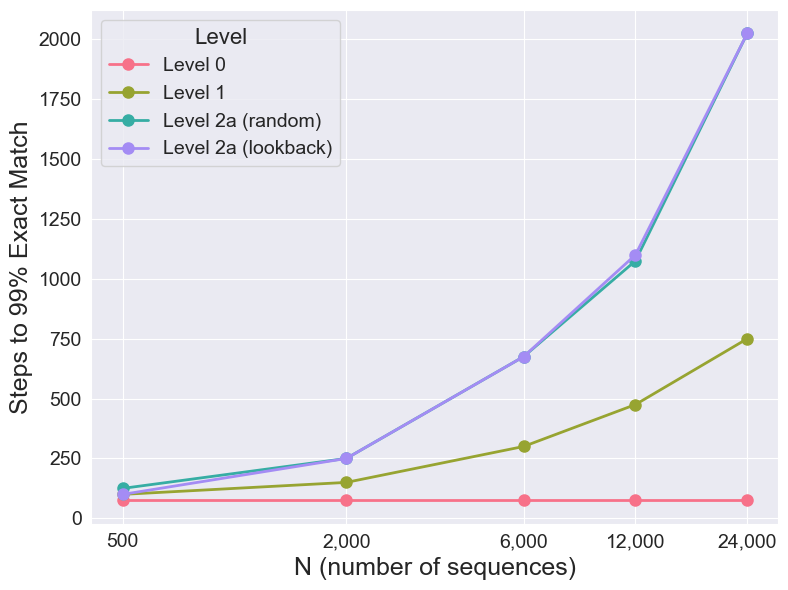

N                    500    2000   6000   12000  24000
level                                                 
Level 0                 75     75     75     75     75
Level 1                100    150    300    475    750
Level 2a (lookback)    100    250    675   1100   2025
Level 2a (random)      125    250    675   1075   2025


,N,level,steps_to_threshold
0,500,Level 0,75
1,500,Level 1,100
2,500,Level 2a (random),125
3,500,Level 2a (lookback),100
4,2000,Level 0,75
5,2000,Level 1,150
6,2000,Level 2a (random),250
7,2000,Level 2a (lookback),250
8,6000,Level 0,75
9,6000,Level 1,300


In [24]:
plot_scaling(data, threshold=.99, save_path="conditions-vary-n_scaling.pdf")